In [37]:
#Import essential libraries
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

In [38]:
#Import arrest data
filepath = "https://docs.google.com/spreadsheets/d/1rOvIKw4w_GWkDtYhFZysdcgPSTzzWPi3tVl2KsS2g7E/export?format=csv&gid=1515840702"

In [39]:
arrest_pitt_df = pd.read_csv(filepath)

In [40]:
#Reduce columns to only necessary ones
arrest_columns = ['AGE', 'GENDER', 'RACE','OFFENSES', 'ARRESTTIME','INCIDENTZONE','INCIDENTNEIGHBORHOOD','X', 'Y']

In [41]:
#Create new dataframe to reference new columns
arrest_pitt_df = arrest_df[arrest_columns]

In [42]:
#Change DATE to datetime in order to make a line graph of arrests by year
arrest_pitt_df = arrest_pitt_df.rename(columns={
    'ARRESTTIME': 'DATE',})

In [43]:
arrest_pitt_df['DATE'] = pd.to_datetime(arrest_pitt_df['DATE'])

In [44]:
arrest_pitt_df['YEAR'] = [x.year for x in arrest_pitt_df['DATE']]

In [45]:
arrest_pitt_by_year = arrest_pitt_df.loc[(arrest_pitt_df['YEAR'] >= 2017) & (arrest_pitt_df['YEAR'] <= 2023)].\
                    groupby(['YEAR']).\
                    aggregate(Offenses = ('OFFENSES','count')).\
                    reset_index().\
                    set_index('YEAR').\
                    copy()

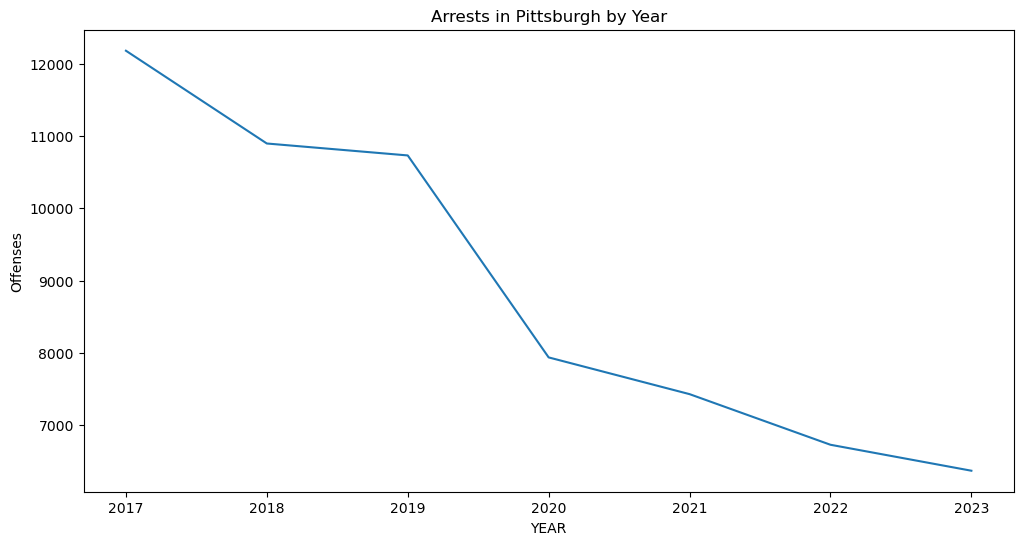

In [46]:
plt.figure(figsize=(12,6))
sns.lineplot(data=arrest_pitt_by_year, x="YEAR", y="Offenses")
plt.title('Arrests in Pittsburgh by Year')
plt.show()

In [47]:
#Plot a bar graph of the total numbers of arrests by zone
arrests_by_zone = arrest_pitt_df.groupby(['INCIDENTZONE']).\
aggregate(arrest_count_zone = ('OFFENSES', 'count')).\
reset_index()

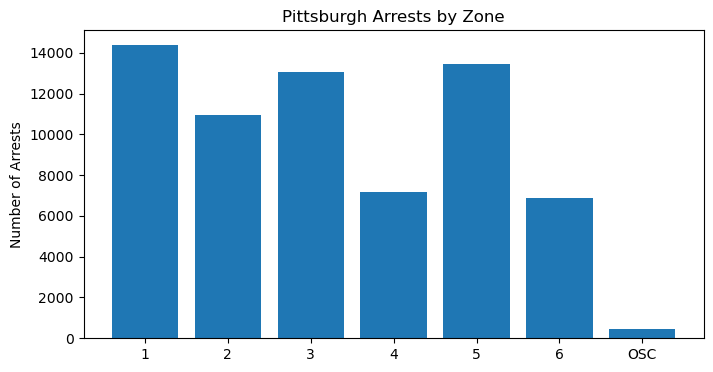

In [48]:
plt.figure(figsize=(8,4))
plt.bar(arrests_by_zone['INCIDENTZONE'],
        arrests_by_zone['arrest_count_zone'],
        0.8)
plt.title('Pittsburgh Arrests by Zone')
plt.ylabel('Number of Arrests')
plt.show()

In [49]:
#Create a condition to filter out only certain type of offense to create new DF 
#Theses can be used to with groupby function to produce sizes for each offense type 
# Example: theft_count_zone = arrest_pitt_df[theft_df].groupby(['INCIDENTZONE']).\
# aggregate(theft_count = ('OFFENSES', 'count')).\
# reset_index() then type "theft_count_zone" to produce results

In [50]:
theft_df = arrest_pitt_df['OFFENSES'].str.contains("Theft|Robbery", na=False)

In [51]:
assault_df = arrest_pitt_df['OFFENSES'].str.contains("Assault", na=False)

In [52]:
possession_df = arrest_pitt_df['OFFENSES'].str.contains("Possession", na=False)

In [53]:
disorderly_df = arrest_pitt_df['OFFENSES'].str.contains("Disorderly Conduct", na=False)

In [54]:
DUI_df = arrest_pitt_df['OFFENSES'].str.contains("DUI", na=False)

In [55]:
property_df = arrest_pitt_df['OFFENSES'].str.contains("Property", na=False)

In [56]:
weapon_df = arrest_pitt_df['OFFENSES'].str.contains("Robbery", na=False)

In [57]:
#Create a stacked bar plot on portion of each type of arrests

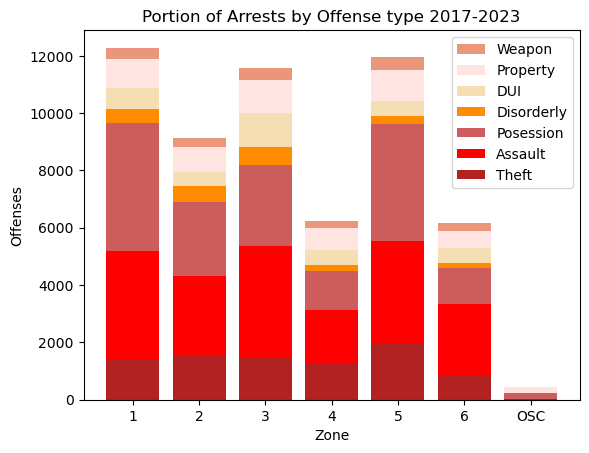

In [58]:
#Create stacked bar plot
x = ['1', '2', '3', '4','5','6', 'OSC']
y1 = np.array([1405, 1573, 1462, 1265, 1990, 864, 15])
y2 = np.array([3768, 2731, 3917, 1852, 3548, 2474, 16])
y3 = np.array([4485,2608, 2829, 1360, 4083, 1261, 208])
y4 = np.array([484, 563, 622, 240, 263, 165, 1])
y5 = np.array([738, 459, 1168, 503, 552, 537, 11])
y6 = np.array([1002, 871, 1171, 768, 1057, 587, 183])
y7 = np.array([401, 337, 415, 261, 474, 275, 1])

# plot bars in stack manner
plt.bar(x, y7, bottom=y1+y2+y3+y4+y5+y6, color='darksalmon')
plt.bar(x, y6, bottom=y1+y2+y3+y4+y5, color='mistyrose')
plt.bar(x, y5, bottom=y1+y2+y3+y4, color='wheat')
plt.bar(x, y4, bottom=y1+y2+y3, color='darkorange')
plt.bar(x, y3, bottom=y1+y2, color='indianred')
plt.bar(x, y2, bottom=y1, color='red')
plt.bar(x, y1, color='firebrick')
plt.xlabel("Zone")
plt.ylabel("Offenses")
plt.legend(["Weapon", "Property", "DUI", "Disorderly", "Posession", "Assault", "Theft"])
plt.title("Portion of Arrests by Offense type 2017-2023")
plt.show()

In [59]:
#Create a Pie Chart for portion of arrests by Offense Type

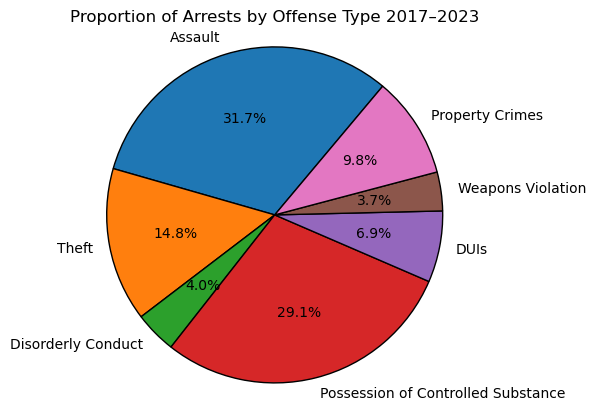

In [60]:
labels = ['Assault', 'Theft', 'Disorderly Conduct', 'Possession of Controlled Substance', 'DUIs', 'Weapons Violation', 'Property Crimes']
sizes = [18339, 8581, 2340, 16856, 3975, 2165, 5660]

# Create the pie chart
fig, ax = plt.subplots()
plt.title("Proportion of Arrests by Offense Type 2017–2023")
ax.pie(sizes, labels=labels, wedgeprops={'edgecolor': 'black'}, startangle=50, autopct='%1.1f%%')
ax.axis('equal')  # Equal aspect ratio ensures a circular pie chart
plt.show()

In [61]:
#Fin